In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
%matplotlib inline

In [2]:
# creating the non linear dataset 
X = 6* np.random.rand(100,1)-3
y= 0.5 * X**2 + 1.5*X + 2 + np.random.randn(100,1)
# quadratic equation (np.random.randn(100,1)) ->  this is the outlier 


Text(0, 0.5, 'y data')

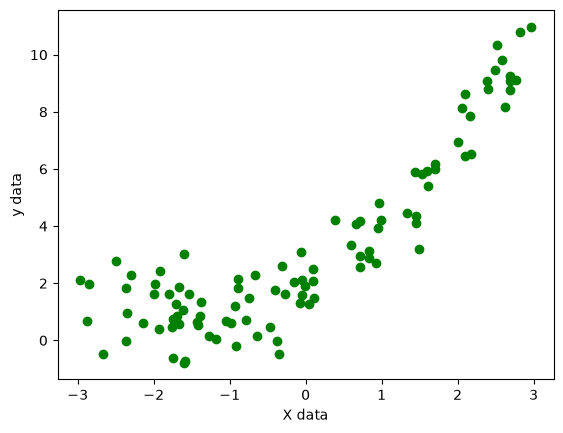

In [3]:
plt.scatter(X, y ,color='g')
plt.xlabel('X data')
plt.ylabel('y data')

In [4]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y , test_size = 0.2, random_state=42)

In [5]:
# lets see the simple linear regression
from sklearn.linear_model import LinearRegression

regression_Linear = LinearRegression()



In [6]:
regression_Linear.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[1.52]]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[3.32]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[14.79]


In [7]:
from sklearn.metrics import r2_score
score  = r2_score(y_test, regression_Linear.predict(X_test))
score

0.8324053545460345

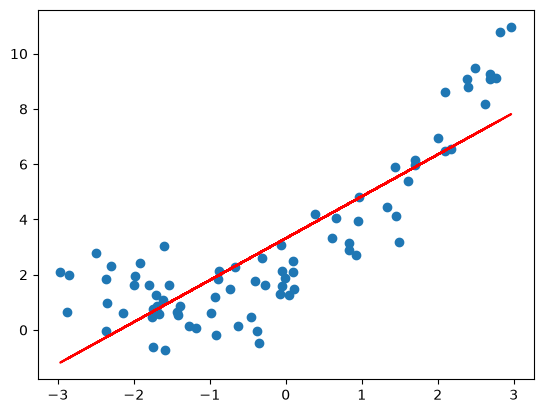

In [8]:
plt.plot(X_train, regression_Linear.predict(X_train),color = 'r')
plt.scatter(X_train, y_train)

In [11]:
from sklearn.preprocessing import PolynomialFeatures
poly = PolynomialFeatures(degree=2 , include_bias=True)

In [12]:
X_train_poly = poly.fit_transform(X_train)

In [13]:
X_test_poly = poly.transform(X_test)

In [16]:
from sklearn.metrics import r2_score
regression = LinearRegression()
regression.fit(X_train_poly, y_train)
y_pred = regression.predict(X_test_poly)
score = r2_score(y_test, y_pred)
print(score)

0.9271603757709159


### Polynomial Pipeline 

In [17]:
from sklearn.pipeline import Pipeline


In [ ]:
def poly_regression(degree):
  X_new = np.linspace(-3 , 3 , 200).reshape(200,1)
  
  poly_features = PolynomialFeatures(degree=5 , include_bias=True)
  lin_reg = LinearRegression()
  poly_regression = Pipeline([
    ("poly_features",poly_features )
    ("lin_reg" ,lin_reg )
  ])
  poly_regression.fit(X_train, y_train)
  y_pred_new = poly_regression.predict(X_new)